In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
h2 = ['gdp', 'inflation', 'agr_land', 'livestock_prod']

### Import the data
* Import data that describe countries in one point

In [3]:
countries_win = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [4]:
countries_win.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


### Delete statistic from list of macros

In [5]:
list(countries_win.columns)

['Country',
 'labor_force_mean',
 'labor_force_median',
 'labor_force_std',
 'labor_force_min',
 'labor_force_max',
 'labor_force_last',
 'livestock_prod_mean',
 'livestock_prod_median',
 'livestock_prod_std',
 'livestock_prod_cv',
 'livestock_prod_min',
 'livestock_prod_max',
 'livestock_prod_last',
 'urban_pop_mean',
 'urban_pop_median',
 'urban_pop_min',
 'urban_pop_max',
 'urban_pop_last',
 'gov_exp_mean',
 'gov_exp_median',
 'gov_exp_std',
 'gov_exp_cv',
 'gov_exp_min',
 'gov_exp_max',
 'gov_exp_last',
 'gov_exp_growth',
 'gov_exp_trend',
 'reserves_mean',
 'reserves_median',
 'reserves_std',
 'reserves_cv',
 'reserves_min',
 'reserves_max',
 'reserves_last',
 'investment_mean',
 'investment_median',
 'investment_std',
 'investment_cv',
 'investment_min',
 'investment_max',
 'investment_last',
 'investment_growth',
 'investment_trend',
 'cpi_mean',
 'cpi_median',
 'cpi_std',
 'cpi_cv',
 'cpi_min',
 'cpi_max',
 'cpi_last',
 'gdp_mean',
 'gdp_median',
 'gdp_std',
 'gdp_cv',
 'gdp_mi

In [6]:
def filter_macro_columns_with_country(df, macro_keywords, keep_column="Country"):
    """
    Conserva solo las columnas del DataFrame que contienen alguna palabra clave en 'macro_keywords',
    además de la columna 'Country'.

    Parámetros:
    - df: pandas.DataFrame
        El DataFrame original con muchas columnas macroeconómicas.
    - macro_keywords: list of str
        Lista de palabras clave que deben estar presentes en el nombre de las columnas a conservar.
    - keep_column: str
        Columna adicional que se desea conservar (por defecto 'Country').

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame con solo las columnas relevantes.
    """

    columnas_filtradas = [
        col for col in df.columns
        if any(keyword in col for keyword in macro_keywords)
    ]

    # Asegurar que 'Country' esté incluido si existe en el DataFrame
    if keep_column in df.columns and keep_column not in columnas_filtradas:
        columnas_filtradas.insert(0, keep_column)

    df_filtrado = df[columnas_filtradas].copy()

    print(f"Columnas conservadas ({len(columnas_filtradas)}): {columnas_filtradas}")
    return df_filtrado

In [7]:
countries_win_h2 = filter_macro_columns_with_country(countries_win, h2)

Columnas conservadas (45): ['Country', 'livestock_prod_mean', 'livestock_prod_median', 'livestock_prod_std', 'livestock_prod_cv', 'livestock_prod_min', 'livestock_prod_max', 'livestock_prod_last', 'gdp_mean', 'gdp_median', 'gdp_std', 'gdp_cv', 'gdp_min', 'gdp_max', 'gdp_last', 'gdp_growth', 'gdp_trend', 'inflation__mean', 'inflation__median', 'inflation__std', 'inflation__cv', 'inflation__max', 'inflation__last', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'gdp_skew', 'gdp_kurtosis', 'inflation__min', 'inflation__growth', 'inflation__skew', 'inflation__kurtosis', 'inflation__trend']


In [8]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from a DataFrame where the value in the specified column matches any country in the given list.

    Parameters:
    - df (pd.DataFrame): The original DataFrame.
    - country_list (list): A list of country names to be removed from the DataFrame.
    - column (str): The name of the column containing country identifiers (default is "Country").

    Returns:
    - pd.DataFrame: A new DataFrame excluding rows where the country is in the provided list.
    """
    return df[~df[column].isin(country_list)].copy()

In [9]:
countries_to_remove = ["Hong-Kong","India","Turkey", "Iceland", "Russia"]

In [10]:
countries_win_h2 = remove_rows_by_countries(countries_win_h2, countries_to_remove)

In [11]:
countries_win_h2.shape

(49, 45)

### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [12]:
from sklearn.cluster import KMeans

In [13]:
from sklearn.metrics import silhouette_samples

In [14]:
from matplotlib import cm

In [15]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [16]:
import country_converter as coco

In [17]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

#### cluster_input_h2

In [18]:
cluster_input_h2 = countries_win_h2.select_dtypes(include='number')
cluster_input_h2.head()

,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,gdp_std,...,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis,inflation__min,inflation__growth,inflation__skew,inflation__kurtosis,inflation__trend
0,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,4.529963,...,-0.755144,0.299427,0.588591,-0.393881,-0.533219,-0.172385,-0.180908,-0.292617,-0.570237,-0.210314
1,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,2.538337,...,0.833938,0.008353,-0.419006,-0.097436,-0.278300,0.151985,-0.365941,0.208691,-0.396264,-0.077660
2,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,2.878367,...,-0.755144,0.405169,0.417570,0.111506,-0.422868,-0.226447,-0.307831,0.842201,1.115577,-0.234500
3,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,6.189334,...,0.061606,-0.670852,-0.592022,-0.013102,-0.531518,0.530417,-0.418923,0.211311,-0.345260,-0.233034
4,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,2.336594,...,0.674399,-0.264767,0.329780,0.304080,-0.121597,0.314170,-0.564481,0.842201,0.848276,-0.199321


In [19]:
countries_win_h2.head()

,Country,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,...,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis,inflation__min,inflation__growth,inflation__skew,inflation__kurtosis,inflation__trend
0,Australia,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,...,-0.755144,0.299427,0.588591,-0.393881,-0.533219,-0.172385,-0.180908,-0.292617,-0.570237,-0.210314
1,Austria,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,...,0.833938,0.008353,-0.419006,-0.097436,-0.278300,0.151985,-0.365941,0.208691,-0.396264,-0.077660
2,Belgium,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,...,-0.755144,0.405169,0.417570,0.111506,-0.422868,-0.226447,-0.307831,0.842201,1.115577,-0.234500
3,Brazil,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,...,0.061606,-0.670852,-0.592022,-0.013102,-0.531518,0.530417,-0.418923,0.211311,-0.345260,-0.233034
4,Bulgaria,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,...,0.674399,-0.264767,0.329780,0.304080,-0.121597,0.314170,-0.564481,0.842201,0.848276,-0.199321


#### Using the elbow method to find the optimal number of clusters

In [20]:
distortions = []

In [21]:
import time

In [22]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


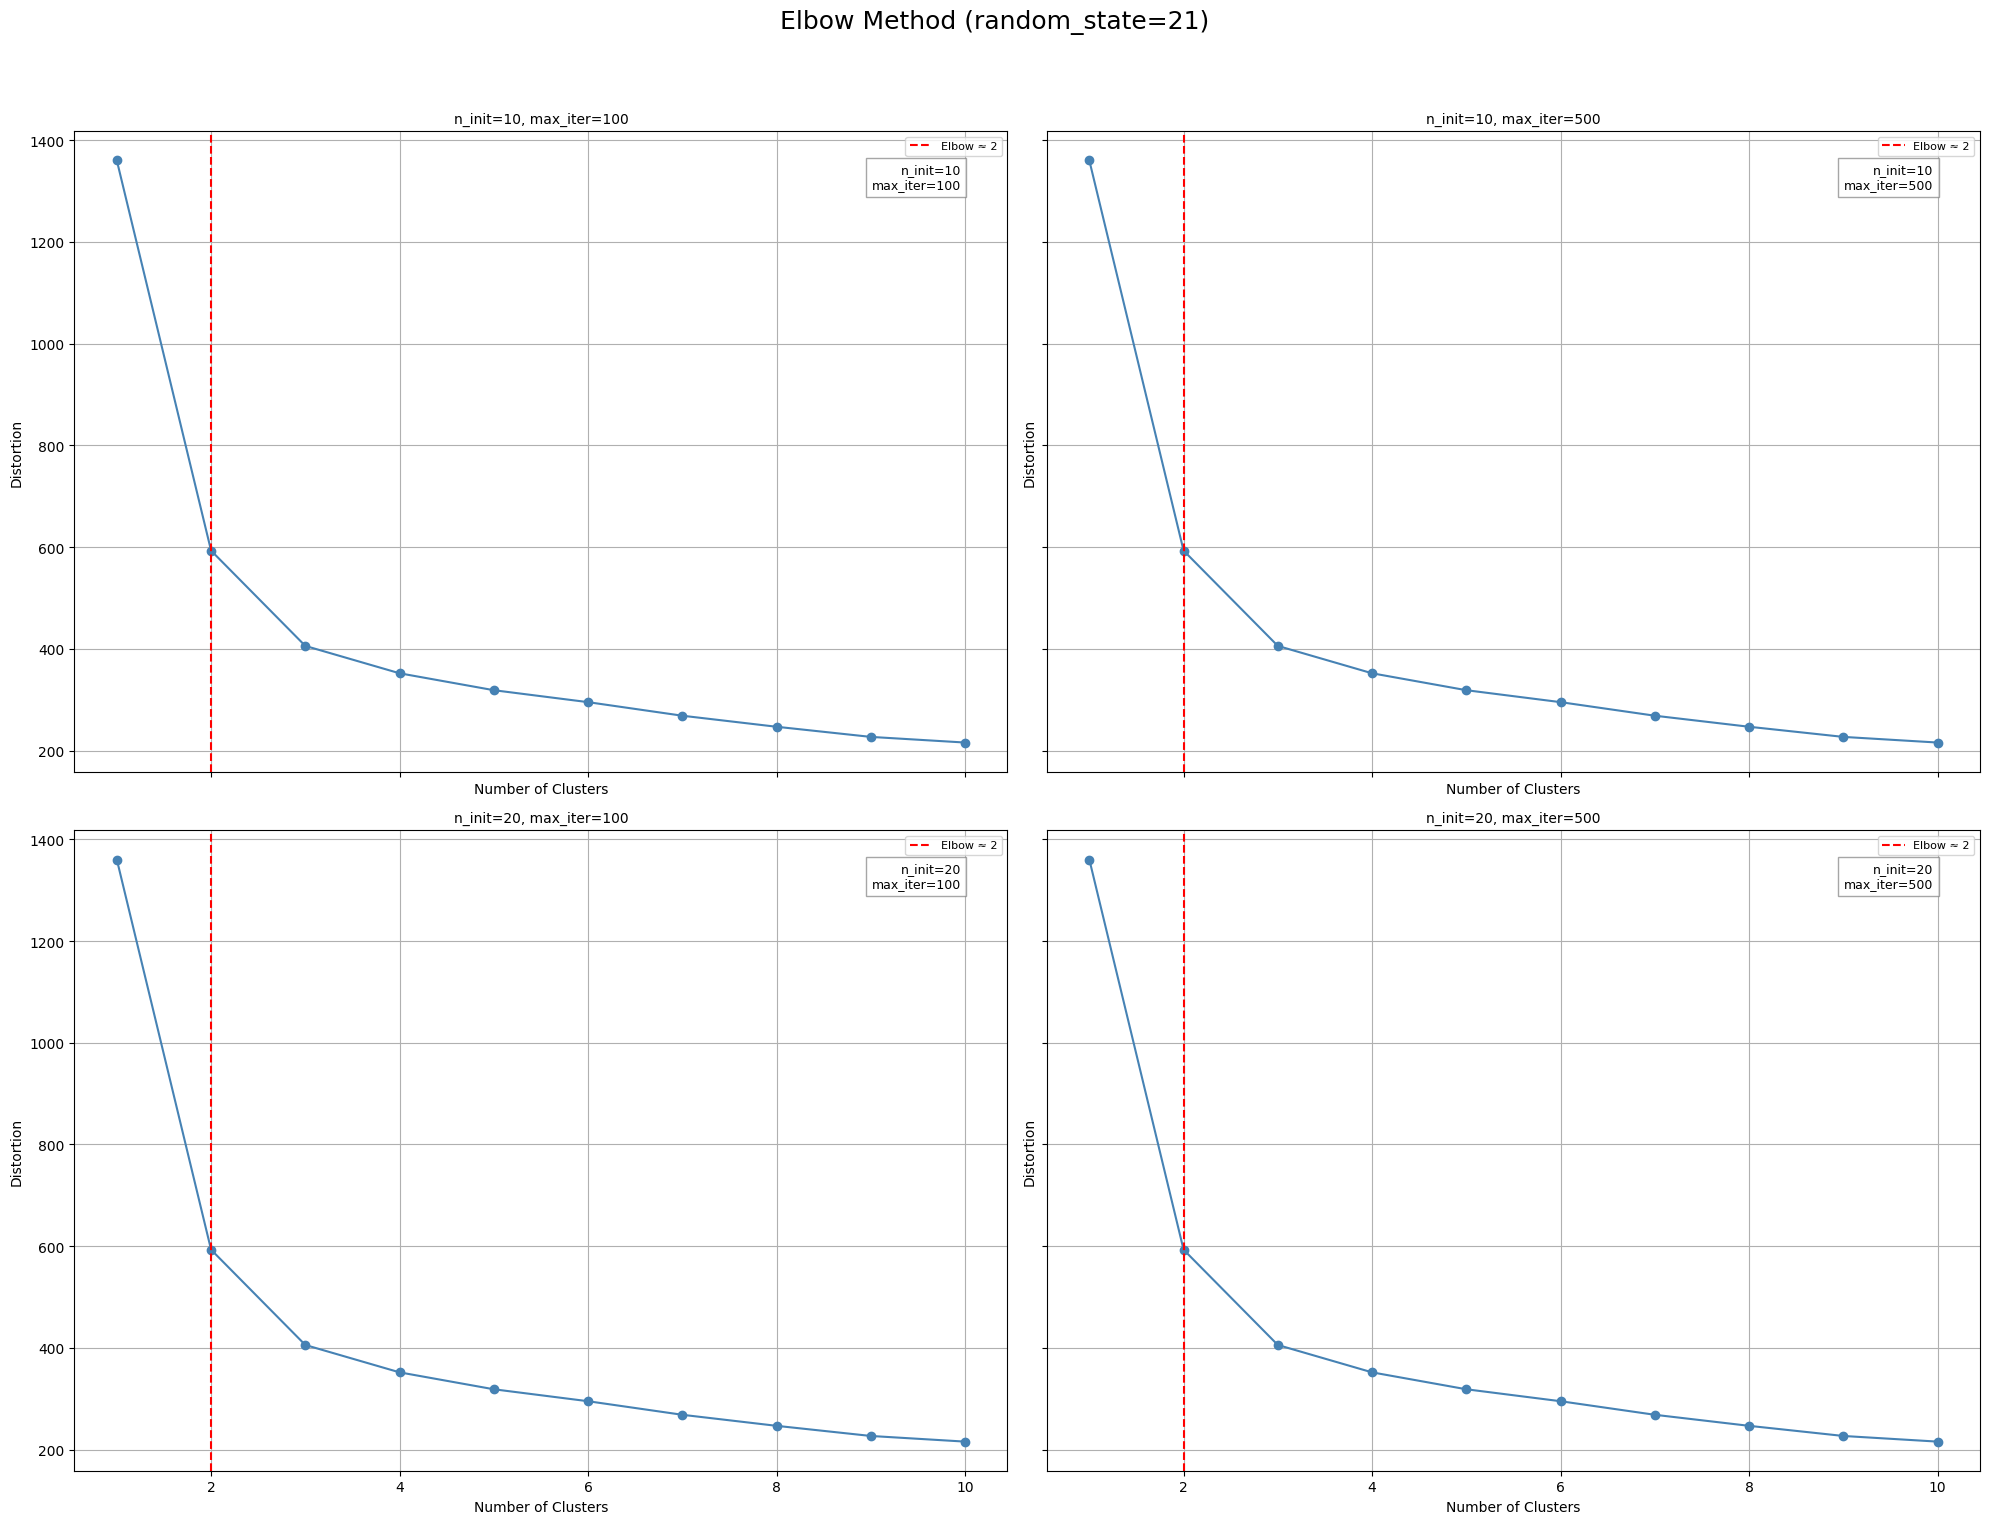


Running elbow plots for random_state=42


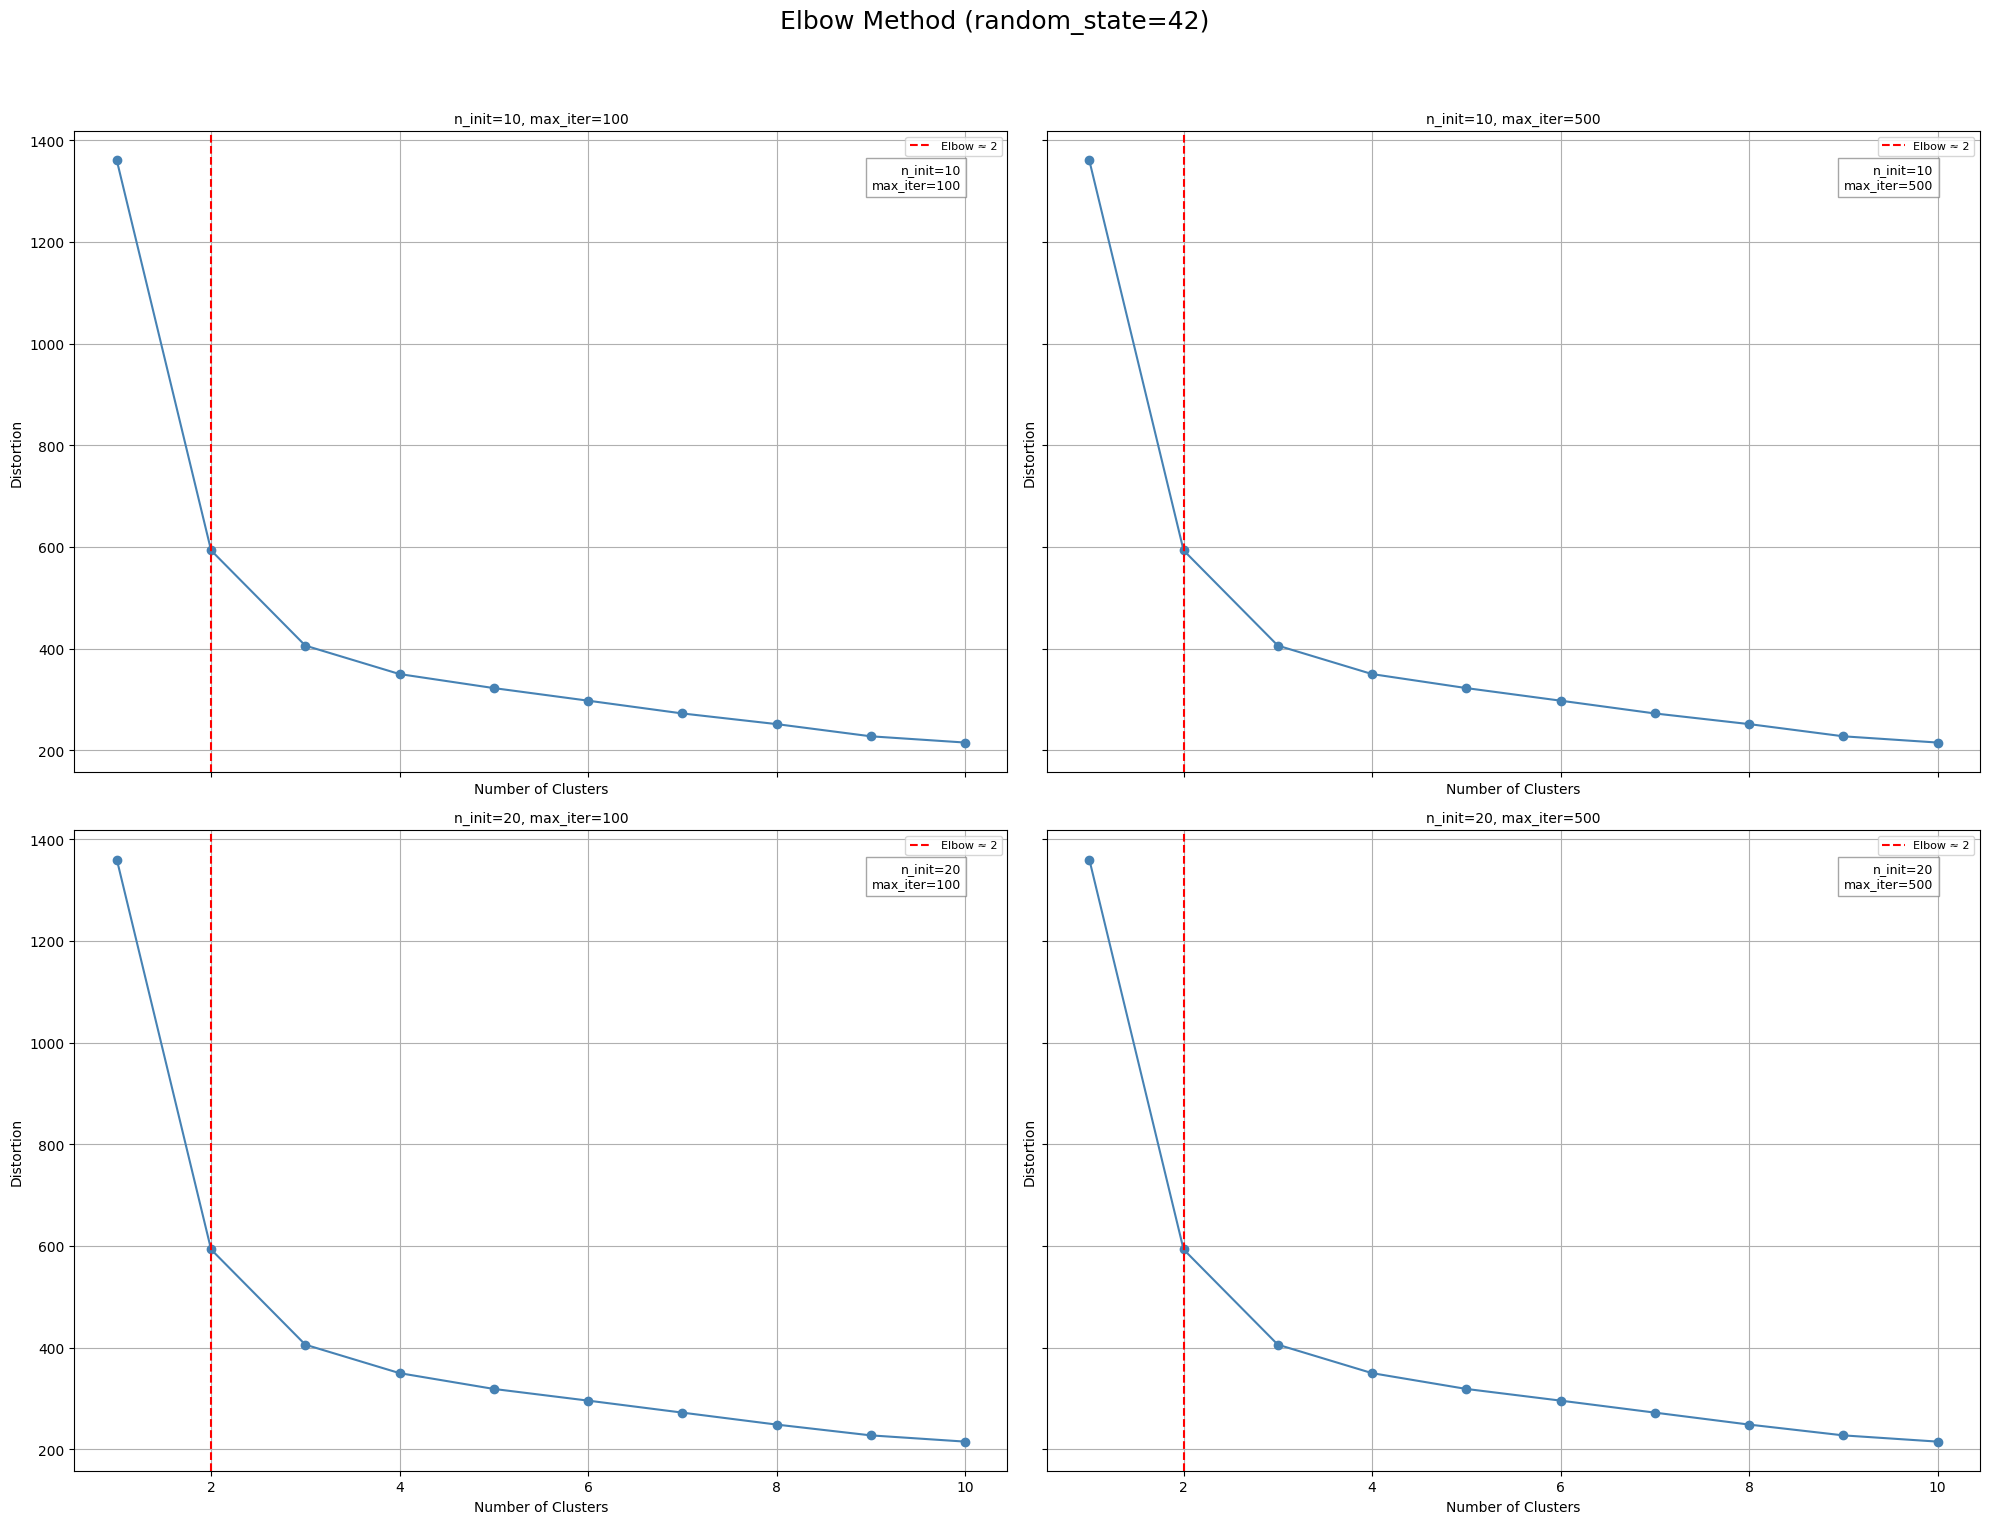


Total execution time: 6.64 seconds


In [23]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input_h2)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [24]:
km_c2_ni20_maxi500_h2 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [25]:
ym_c2_ni20_maxi500_h2 = km_c2_ni20_maxi500_h2.fit(cluster_input_h2)

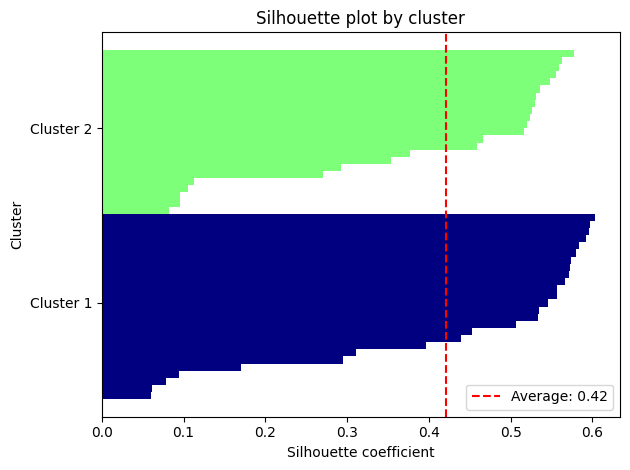

In [26]:
silhoutte_c2_ni20_maxi500_h2 = plot_silhouette(ym_c2_ni20_maxi500_h2, cluster_input_h2)

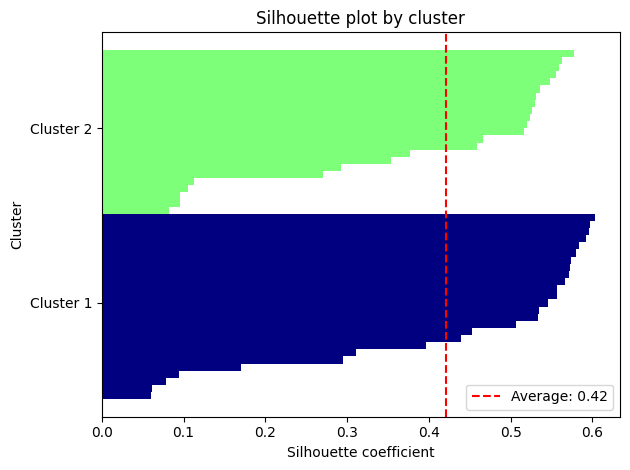

In [27]:
silhoutte_c2_ni20_maxi500_h2 = plot_silhouette(ym_c2_ni20_maxi500_h2, cluster_input_h2)

In [28]:
np.bincount(ym_c2_ni20_maxi500_h2.labels_)

array([26, 23])

In [29]:
c2_ni20_maxi500_h2 = countries_win_h2.copy()

In [30]:
c2_ni20_maxi500_h2['cluster'] = ym_c2_ni20_maxi500_h2.labels_

In [31]:
c2_ni20_maxi500_h2['ISO_A3'] = coco.convert(names=c2_ni20_maxi500_h2['Country'], to='ISO3')

In [32]:
clusters_c2_ni20_maxi500_h2 = c2_ni20_maxi500_h2[['Country', 'ISO_A3', 'cluster']].copy()

In [33]:
clusters_c2_ni20_maxi500_h2.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni20_maxi500_h2['Country'], to='continent'
)

In [34]:
print_cluster_groups(clusters_c2_ni20_maxi500_h2)


🌍 Cluster 0 (26 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malaysia (Asia)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 - Romania (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - Spain (Europe)
 - Switzerland (Europe)

🌍 Cluster 1 (23 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Japan (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea (Asia)
 - Sweden (Europe)
 - Thailand (

In [35]:
clusters_c2_ni20_maxi500_h2['Country'] = clusters_c2_ni20_maxi500_h2['Country'].replace('Czech','Czech Republic')

In [36]:
clusters_c2_ni20_maxi500_h2.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_h2_without4_countries.parquet')

#### c3_ni20_maxi500_h2

In [37]:
km_c3_ni20_maxi500_h2 = KMeans(n_clusters=3,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [38]:
ym_c3_ni20_maxi500_h2 = km_c3_ni20_maxi500_h2.fit(cluster_input_h2)

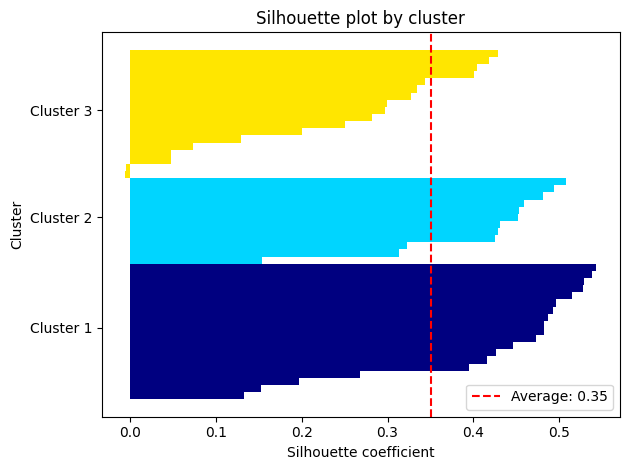

In [39]:
silhoutte_c3_ni20_maxi500_h2 = plot_silhouette(ym_c3_ni20_maxi500_h2, cluster_input_h2)

In [40]:
# Calculate silhouette scores for each sample
silhouette_vals = silhouette_samples(cluster_input_h2, ym_c3_ni20_maxi500_h2.labels_)

# Add silhouette scores to the DataFrame
c2_ni20_maxi500_h2['silhouette_score'] = silhouette_vals

# Filter rows with negative silhouette scores
negative_silhouette = c2_ni20_maxi500_h2[c2_ni20_maxi500_h2['silhouette_score'] < 0]

# Display or inspect the rows with negative silhouette scores
print(negative_silhouette)

   Country  livestock_prod_mean  livestock_prod_median  livestock_prod_std  \
10   Czech             4.622519               4.623992            1.027869   
34    Peru             4.709440               4.731362            2.047482   

    livestock_prod_cv  livestock_prod_min  livestock_prod_max  \
10           0.017337            4.604170            4.645352   
34           0.057789            4.598146            4.761319   

    livestock_prod_last  gdp_mean  gdp_median  ...  gdp_skew  gdp_kurtosis  \
10             4.627910  7.328789    7.289370  ... -0.353473     -0.220029   
34             4.761319  5.324274    5.250721  ... -0.253948     -0.180131   

    inflation__min  inflation__growth  inflation__skew  inflation__kurtosis  \
10        0.530417          -0.564481         0.674785             0.293897   
34        0.206047          -0.564481        -0.115779            -0.365180   

    inflation__trend  cluster  ISO_A3  silhouette_score  
10          0.129018        1     CZE 

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [41]:
clusters_c2_ni20_maxi500_h2.shape

(49, 4)

In [42]:
df_hpi = pd.read_parquet('../data/clean_hpi.parquet')

In [43]:
df_hpi.shape

(15, 58)

In [44]:
def remove_columns_by_list(df, column_list):
    """
    Removes columns from a DataFrame whose names are included in the provided list.
    Also returns a list of column names from the input list that were not found in the DataFrame.

    Parameters:
    - df (pd.DataFrame): The original DataFrame.
    - column_list (list): A list of column names to be removed.

    Returns:
    - filtered_df (pd.DataFrame): A new DataFrame without the specified columns.
    - missing_columns (list): A list of column names from 'column_list' that were not found in the DataFrame.
    """
    existing_columns = set(df.columns)
    missing_columns = [col for col in column_list if col not in existing_columns]
    columns_to_remove = [col for col in column_list if col in existing_columns]
    filtered_df = df.drop(columns=columns_to_remove).copy()
    return filtered_df, missing_columns

In [45]:
df_hpi, missing_columns = remove_columns_by_list(df_hpi, countries_to_remove)

In [46]:
missing_columns

[]

In [47]:
df_hpi.shape

(15, 53)

In [48]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [49]:
missing_countries_5 = find_countries_missing_from_clusters(df_hpi, clusters_c2_ni20_maxi500_h2)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Czech-Republic
 - Indonesia
 - Macedonia
 - Morocco
 - New-Zealand
 - South-Africa
 - South-Korea
 - United-Kingdom
 - Year


In [50]:
countries_to_remove2 = ['Indonesia', 'China', 'Macedonia', 'Morocco']

In [51]:
df_hpi, missing_columns = remove_columns_by_list(df_hpi, countries_to_remove2)

In [52]:
def replace_country_names(df):
    """
    Replaces specific values in the 'Country' column based on their appearance order.
    Handles repeated ambiguous entries like 'South' by assigning distinct names based on position.

    Parameters:
    - df (pd.DataFrame): The original DataFrame containing a 'Country' column.

    Returns:
    - pd.DataFrame: A new DataFrame with updated country names.
    """
    df = df.copy()

    # Dictionary of direct replacements
    replacements = {
        "Czech Republic": "Czech-Republic",
        "New Zealand": "New-Zealand",
        "United Kingdom": "United-Kingdom"
    }

    # List of replacements for ambiguous 'South' entries
    south_replacements = ["South-Africa", "South-Korea"]
    south_index = 0

    def clean_name(name):
        nonlocal south_index
        name = name.strip()
        if "South" in name:
            if south_index < len(south_replacements):
                new_name = south_replacements[south_index]
                south_index += 1
                return new_name
            else:
                return name  # fallback if more than two "South" entries
        return replacements.get(name, name)

    df["Country"] = df["Country"].astype(str).apply(clean_name)
    return df

In [53]:
clusters_c2_ni20_maxi500_h2 = replace_country_names(clusters_c2_ni20_maxi500_h2)

In [54]:
missing_countries_5 = find_countries_missing_from_clusters(df_hpi, clusters_c2_ni20_maxi500_h2)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


In [55]:
clusters_c2_ni20_maxi500_h2.shape

(49, 4)

In [56]:
df_hpi.shape

(15, 49)

### Apply transformation over hpi index
* Apply winsorization
* Apply round to two decimal
* Plot boxplot for every year

In [57]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

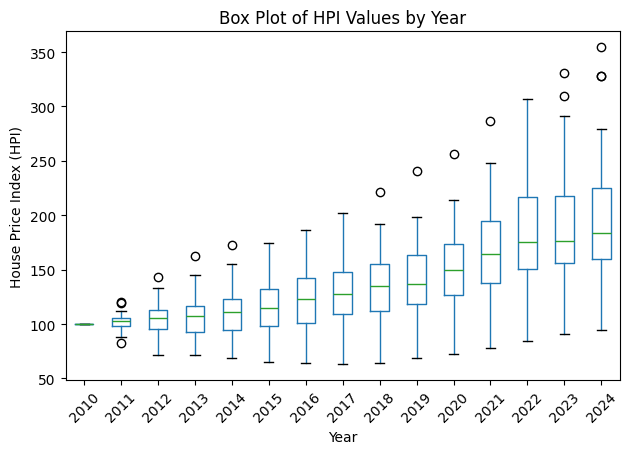

In [58]:
plot_hpi_boxplots_by_year(df_hpi)

In [59]:
from scipy.stats.mstats import winsorize

In [60]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [61]:
df_hpi_win1 = round_and_winsorize_hpi(df_hpi)

<Figure size 1400x600 with 0 Axes>

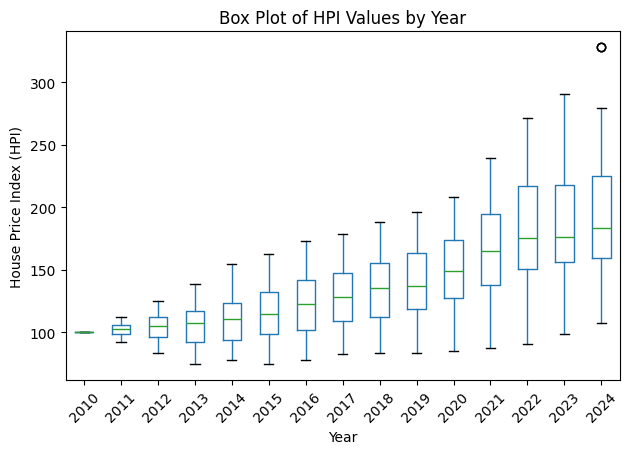

In [62]:
plot_hpi_boxplots_by_year(df_hpi_win1)

In [63]:
df_hpi_win2 = round_and_winsorize_hpi(df_hpi_win1, limits=(0.07, 0.07))

<Figure size 1400x600 with 0 Axes>

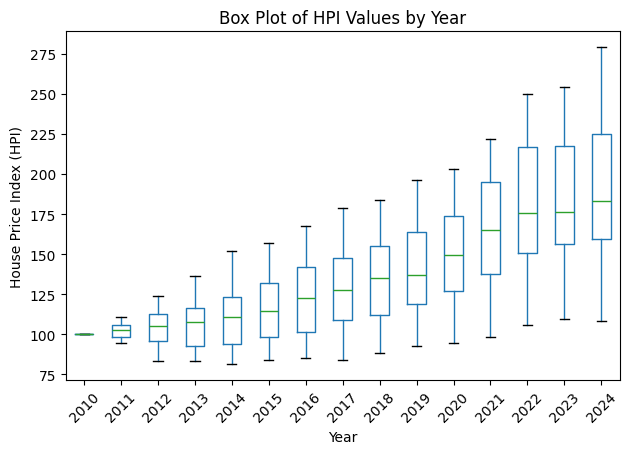

In [64]:
plot_hpi_boxplots_by_year(df_hpi_win2)

In [85]:
df_hpi_win2.to_parquet("../data/hpi_4countries_deleted_2win_005_007.parquet")

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [65]:
import random

In [66]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [67]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='cluster', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [68]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Cluster {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [69]:
def percentage_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                            cluster_column='cluster', country_column='Country',
                                            year_column='Year'):
    """
    Calcula el porcentaje de puntos de HPI que están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y porcentaje de puntos dentro del IQR como valor
    """
    cluster_iqr_percentages = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_percentages[cluster_id] = 0.0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0
        total_values = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count_within_iqr = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count_within_iqr
            total_values += len(values)

        # Calcular porcentaje
        percentage = (total_within_iqr / total_values * 100) if total_values > 0 else 0.0
        cluster_iqr_percentages[cluster_id] = round(percentage, 2)

    return cluster_iqr_percentages


In [70]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [71]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Sampling experiment

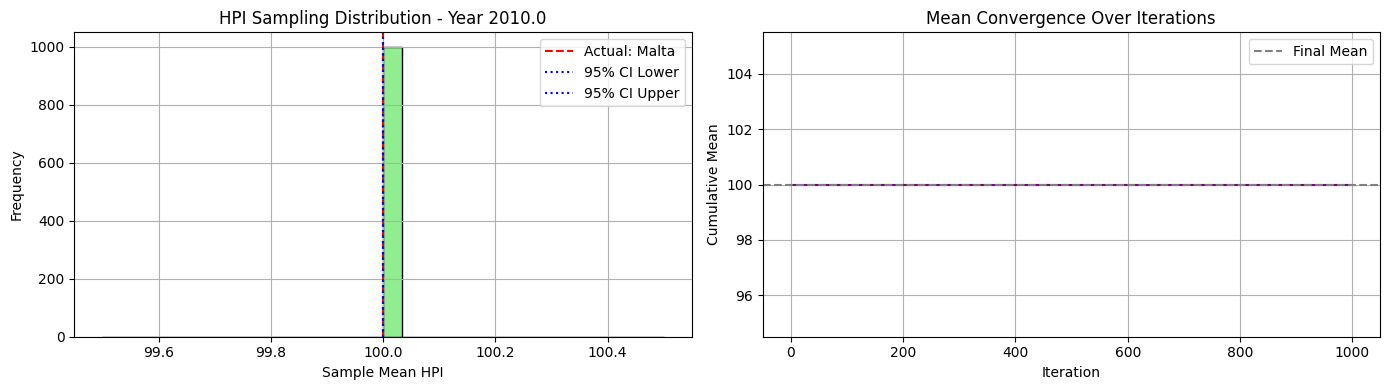

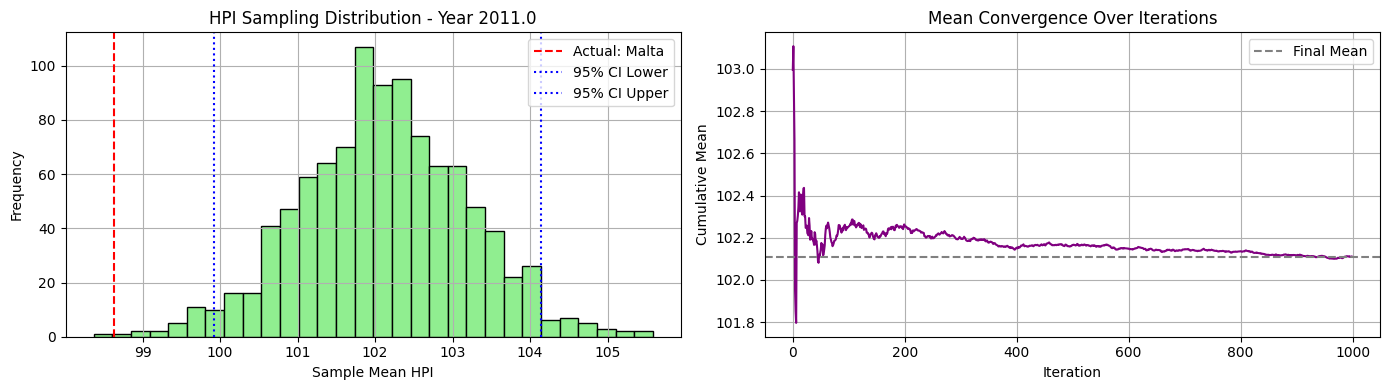

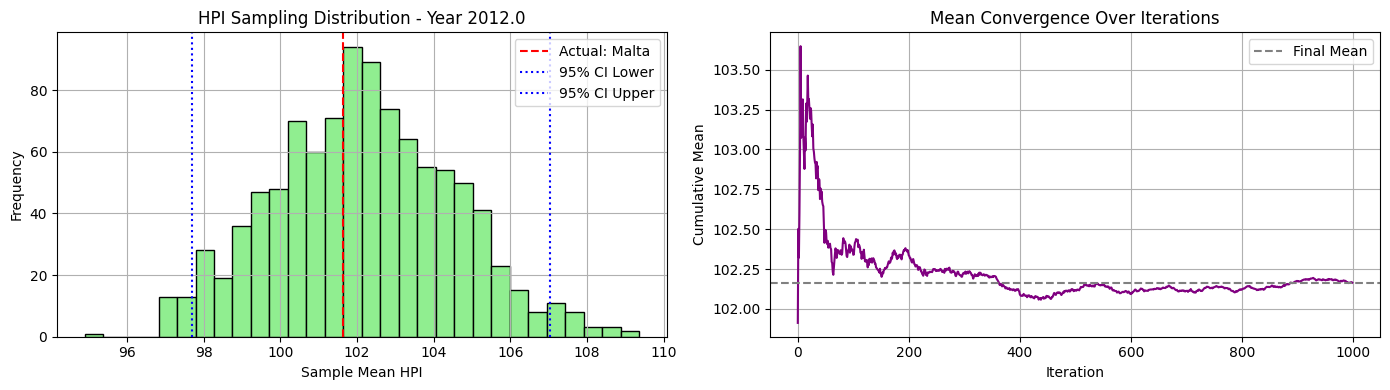

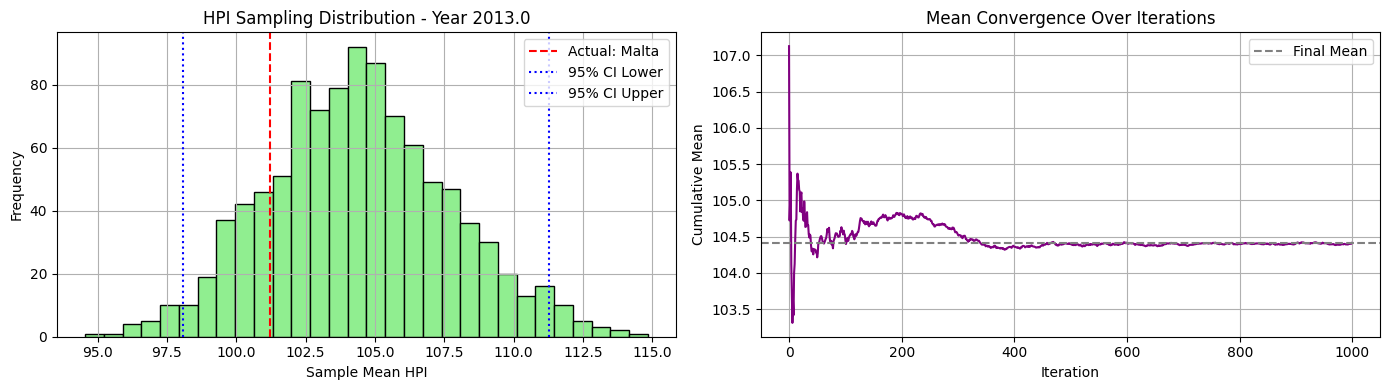

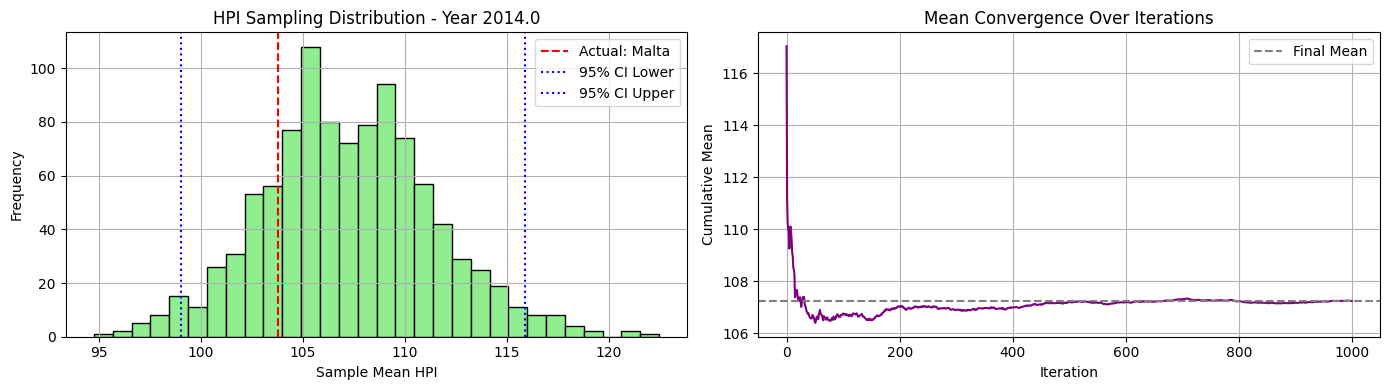

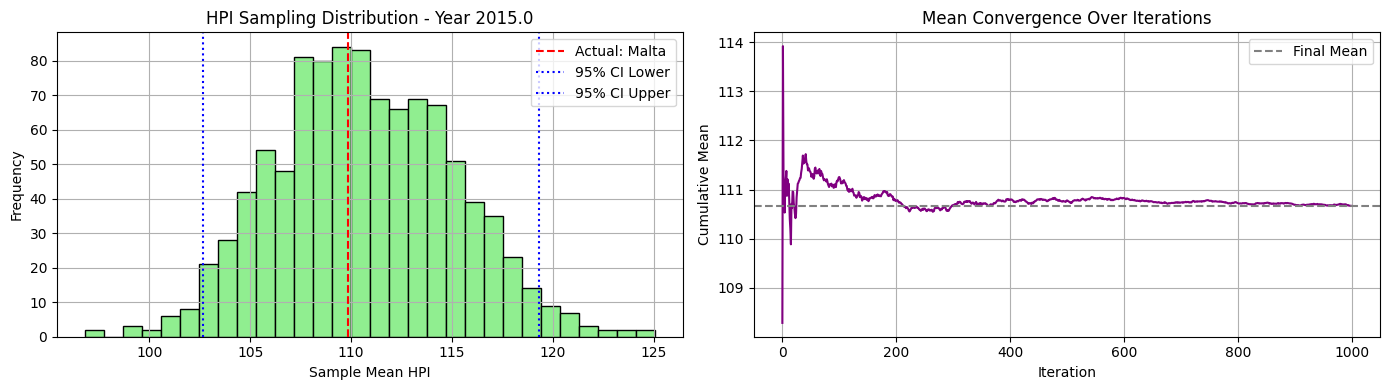

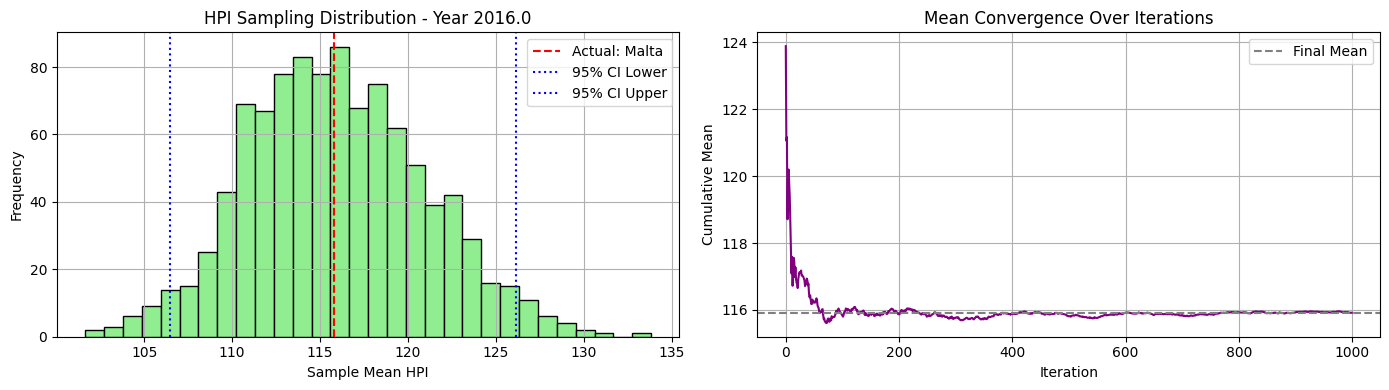

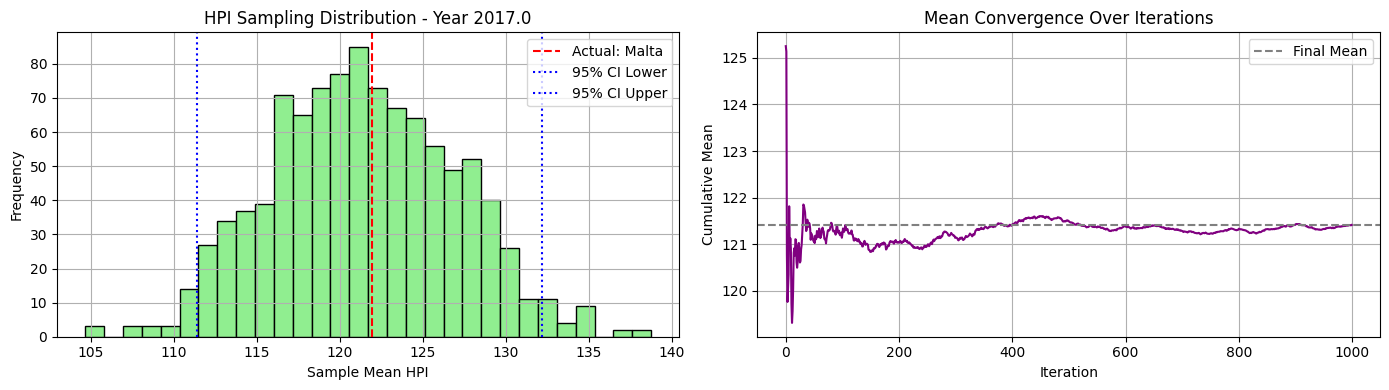

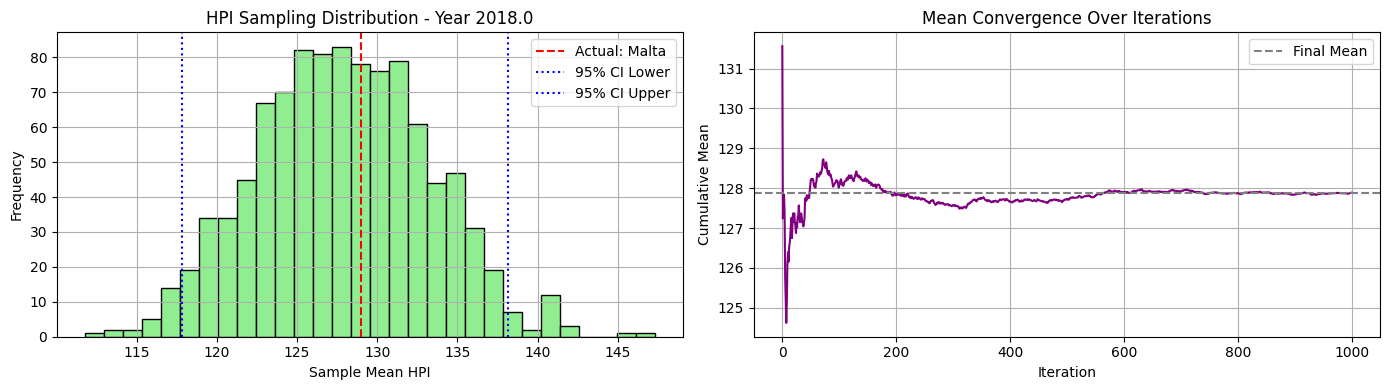

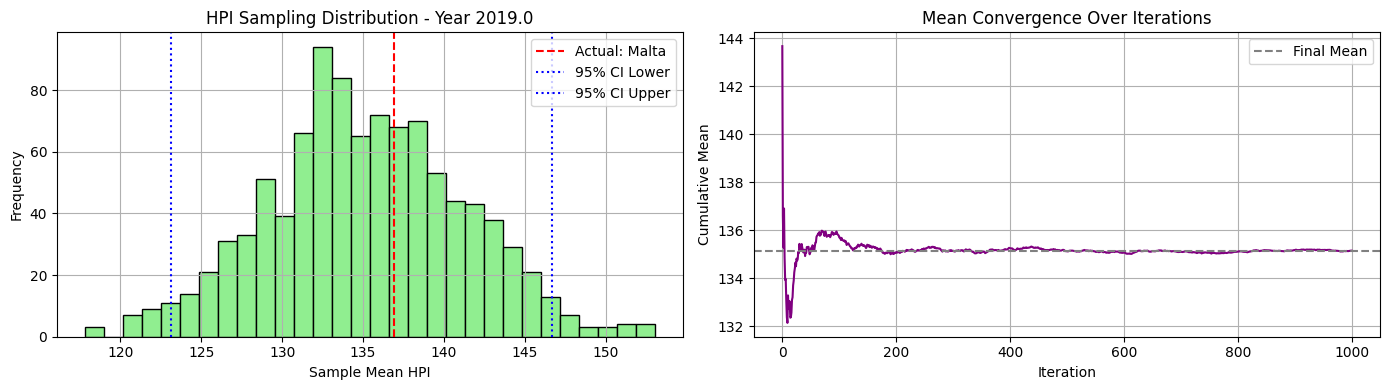

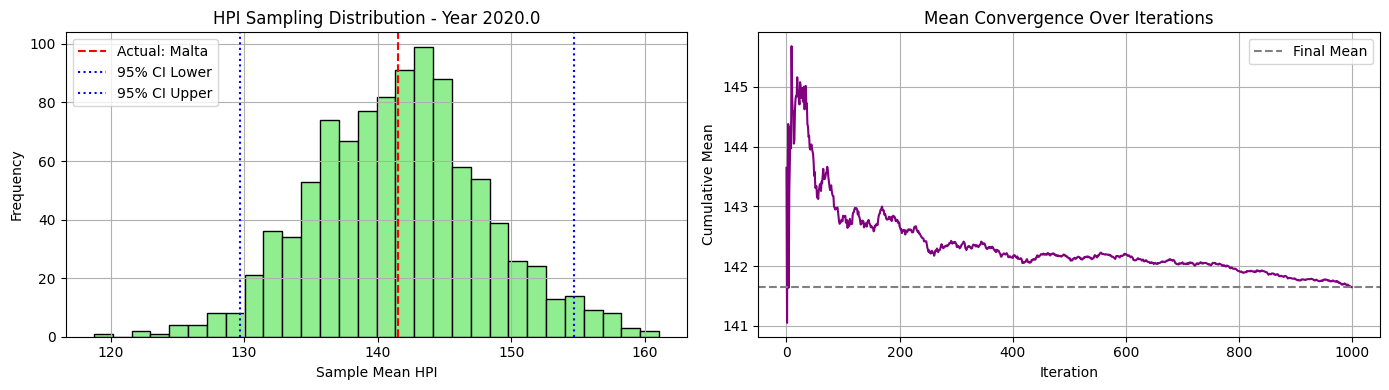

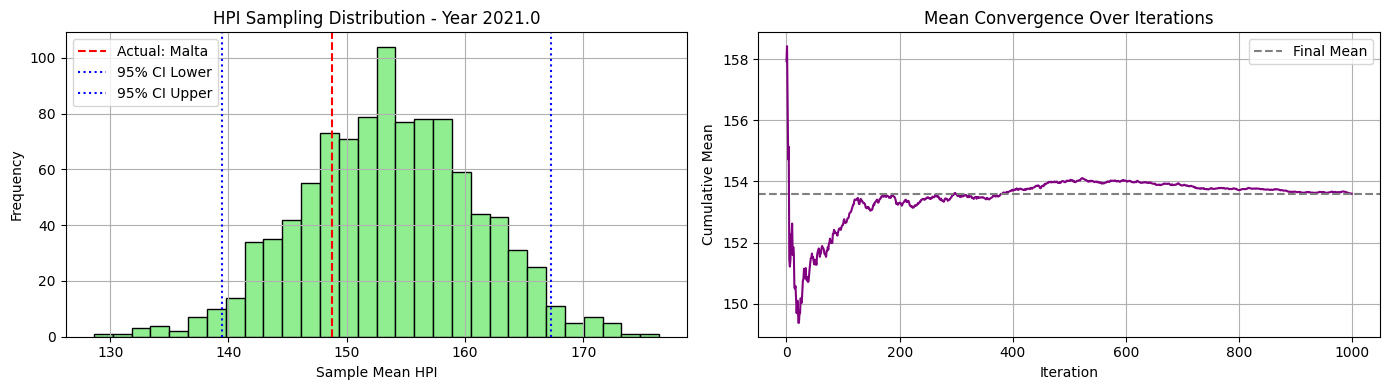

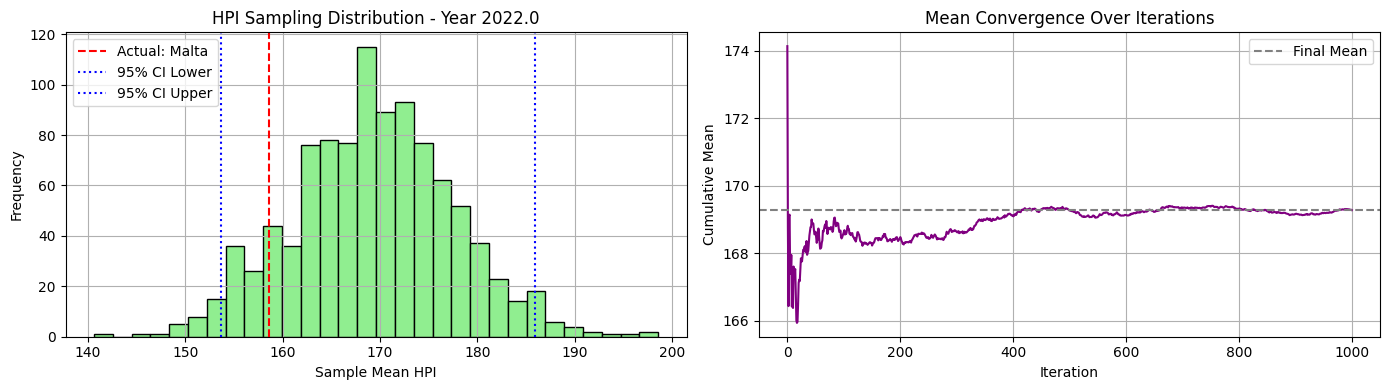

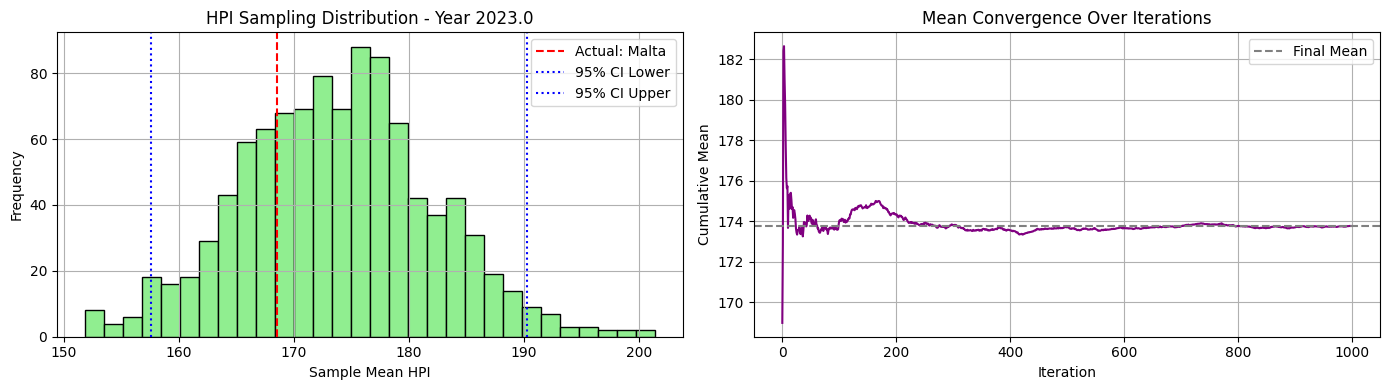

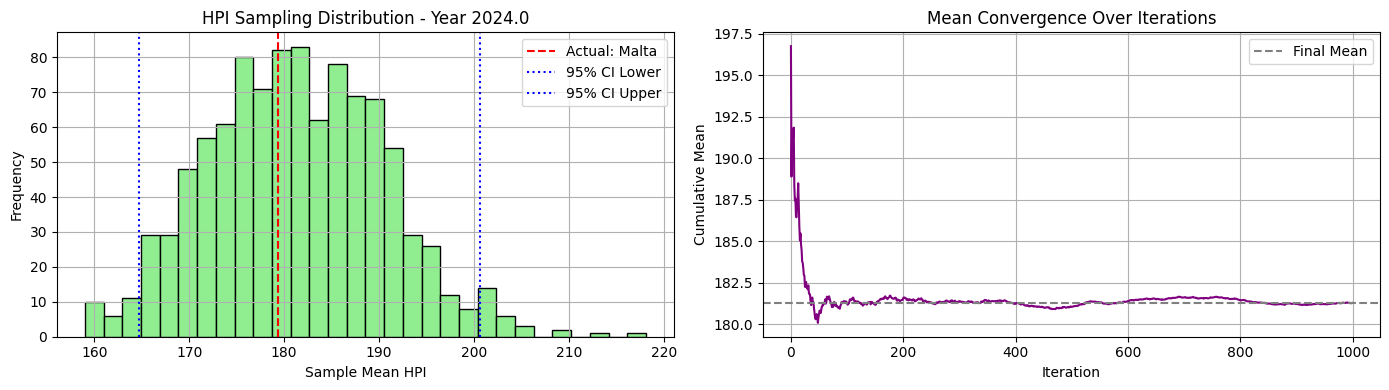

In [72]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=0)

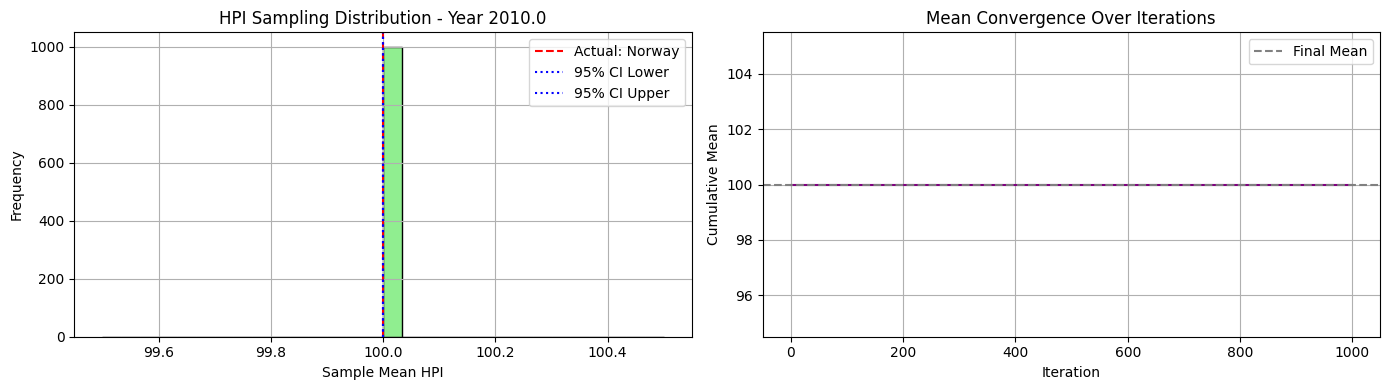

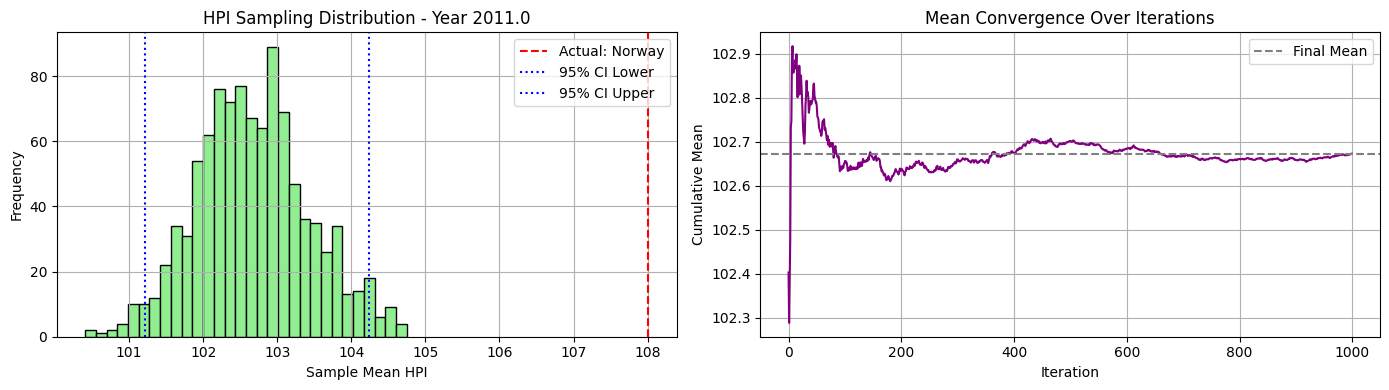

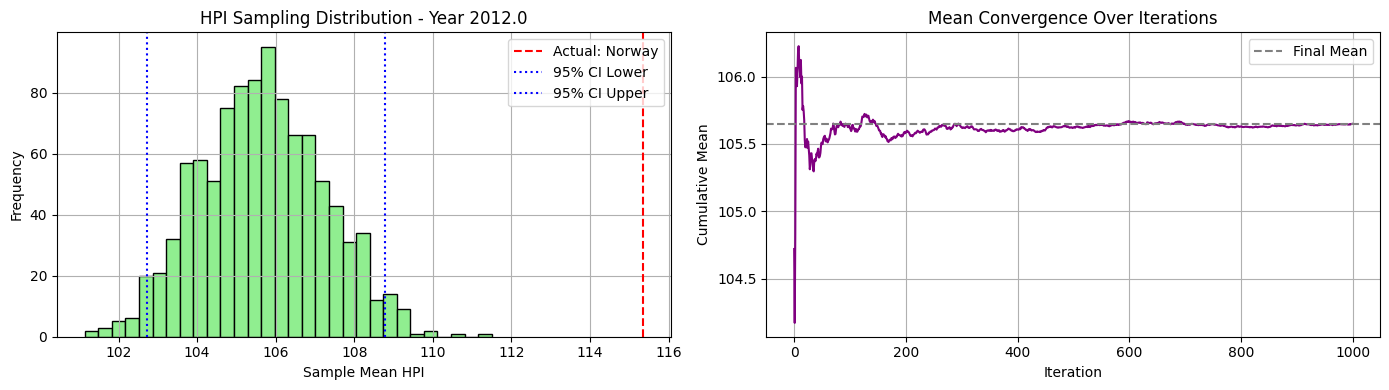

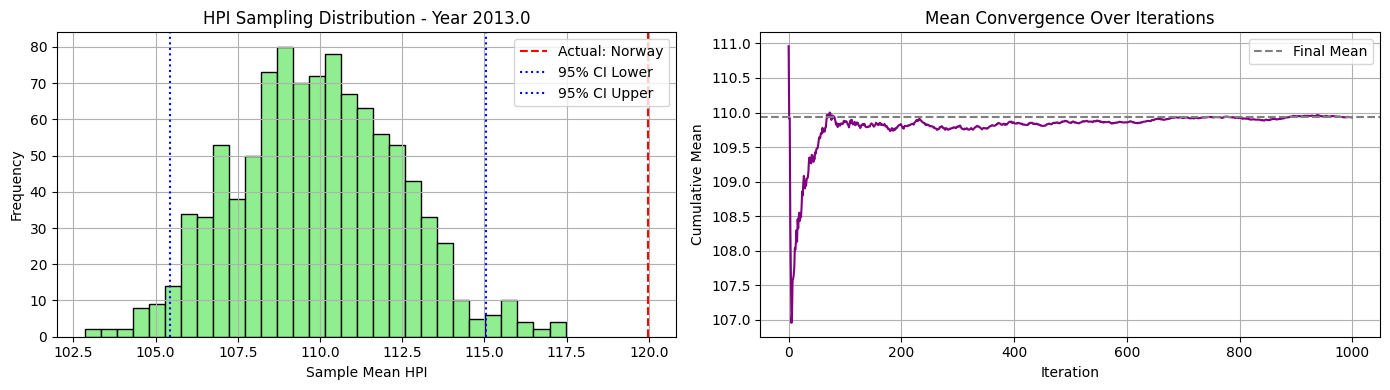

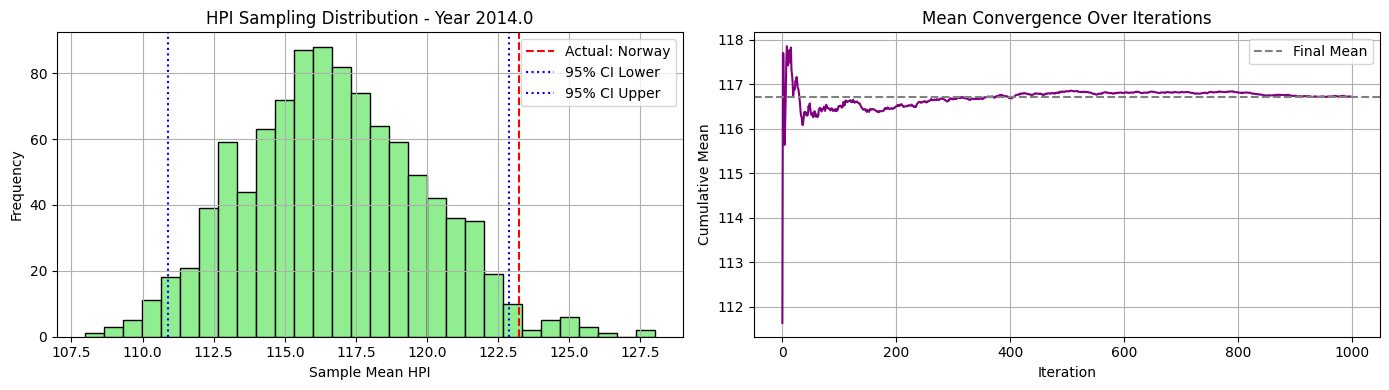

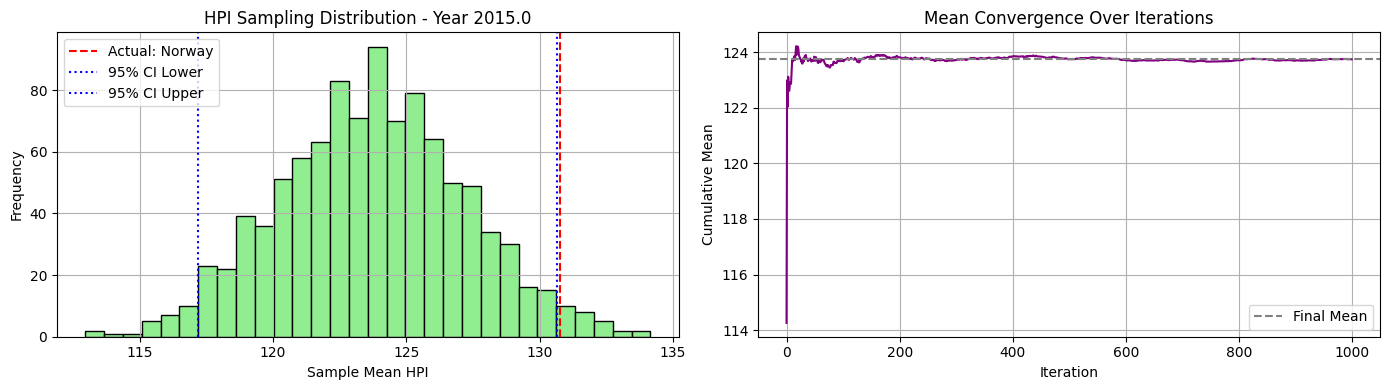

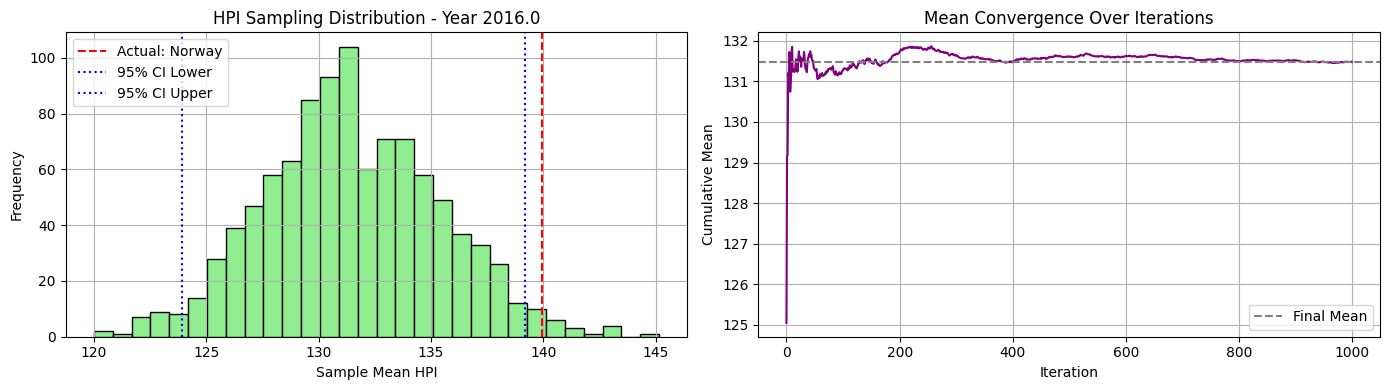

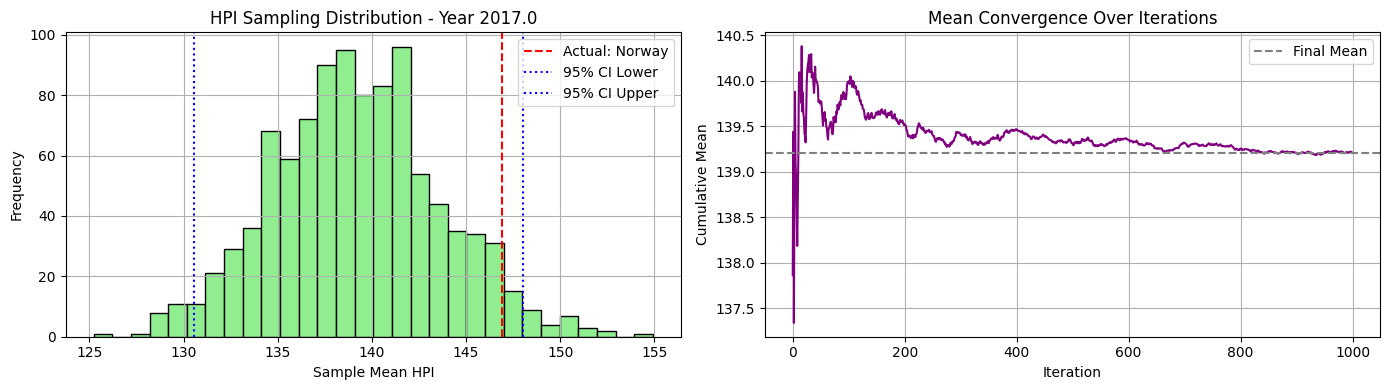

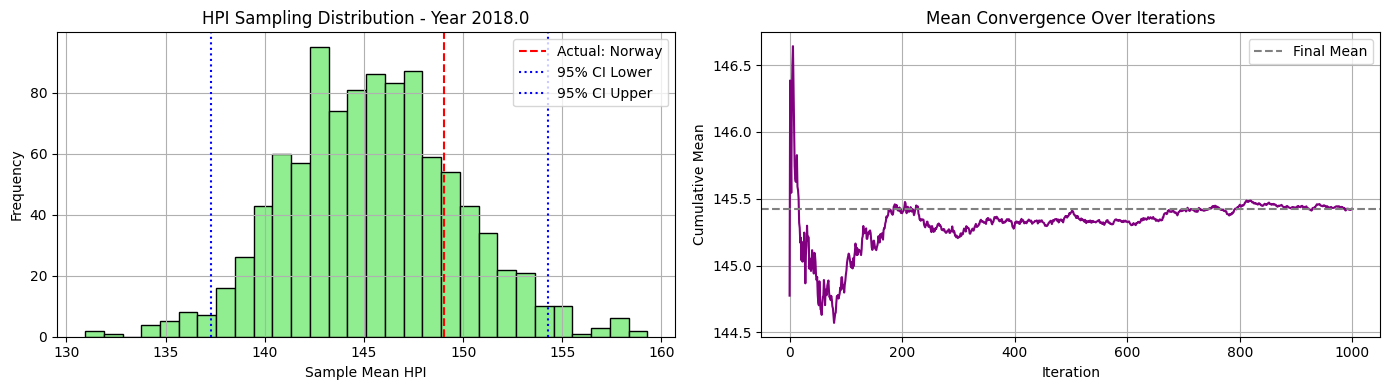

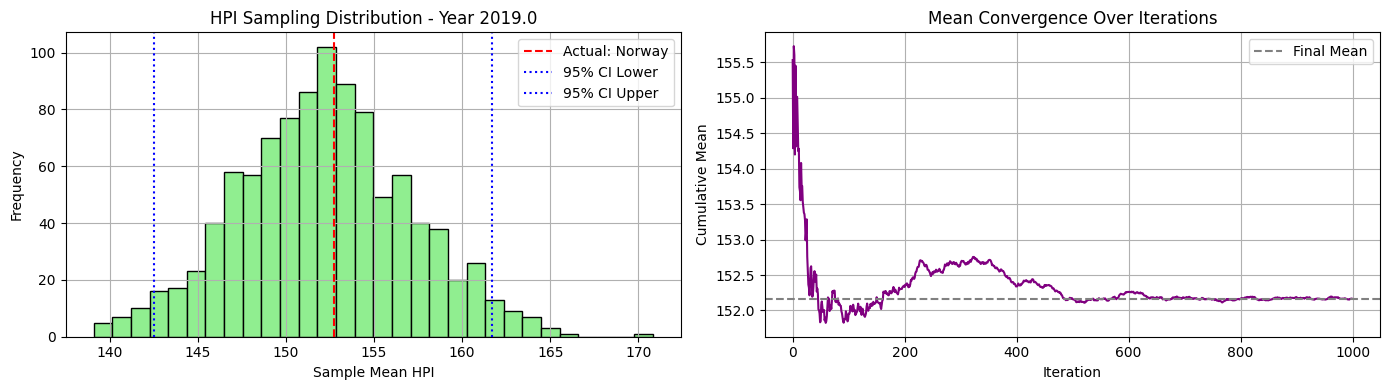

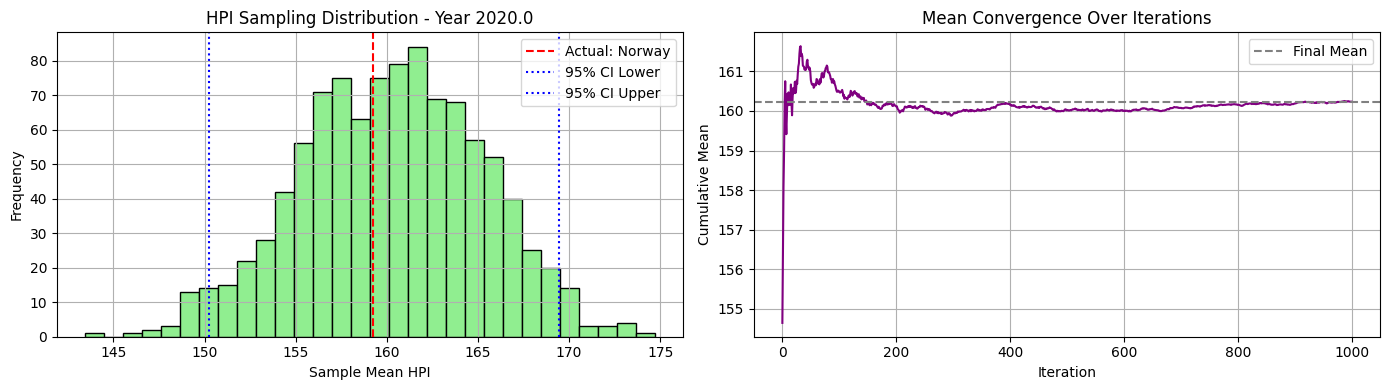

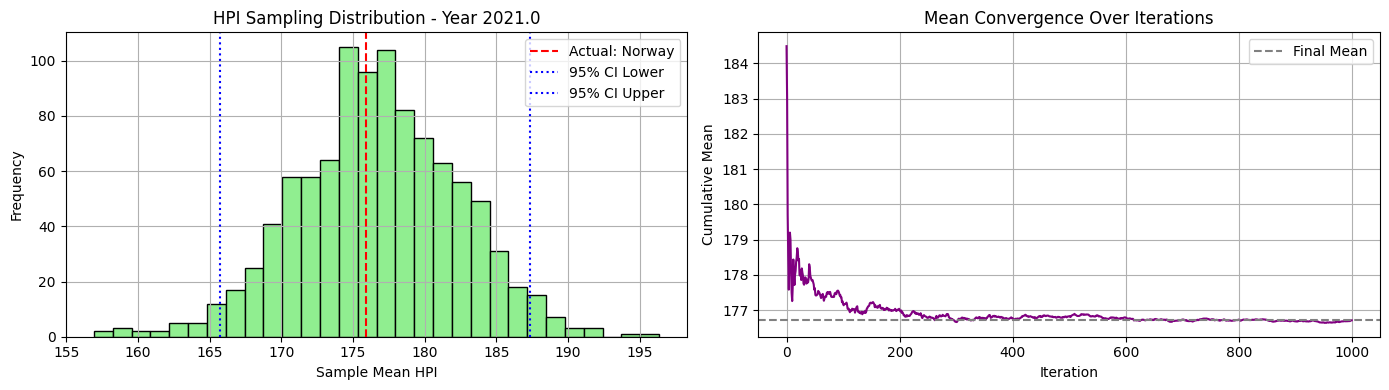

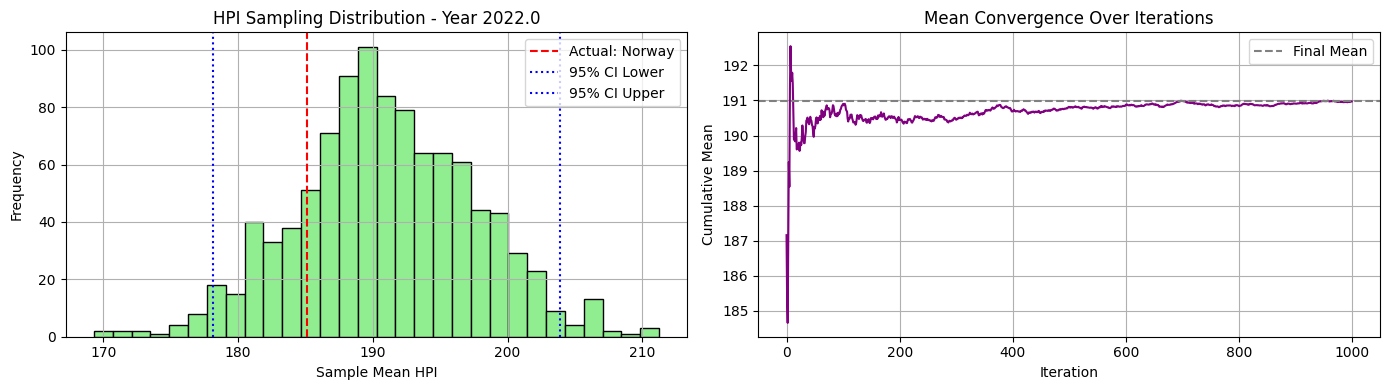

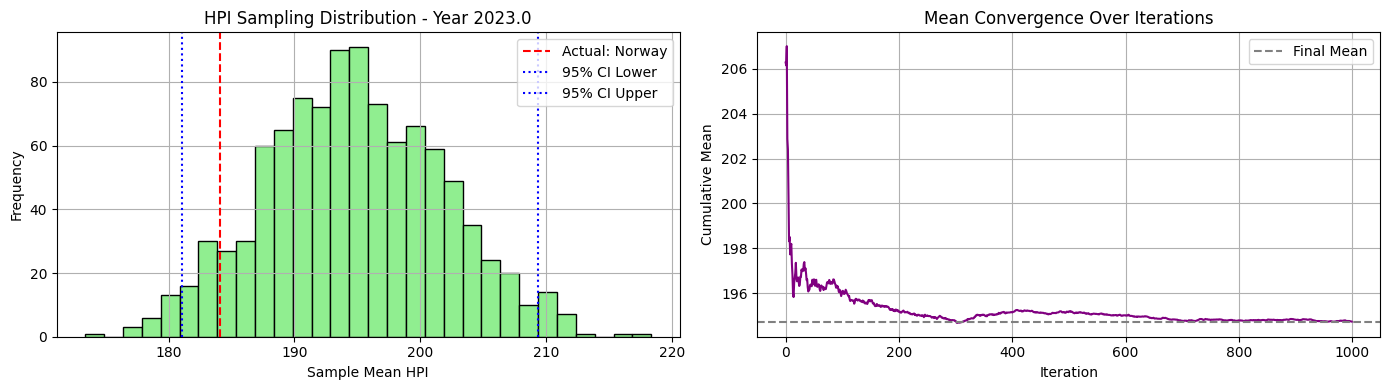

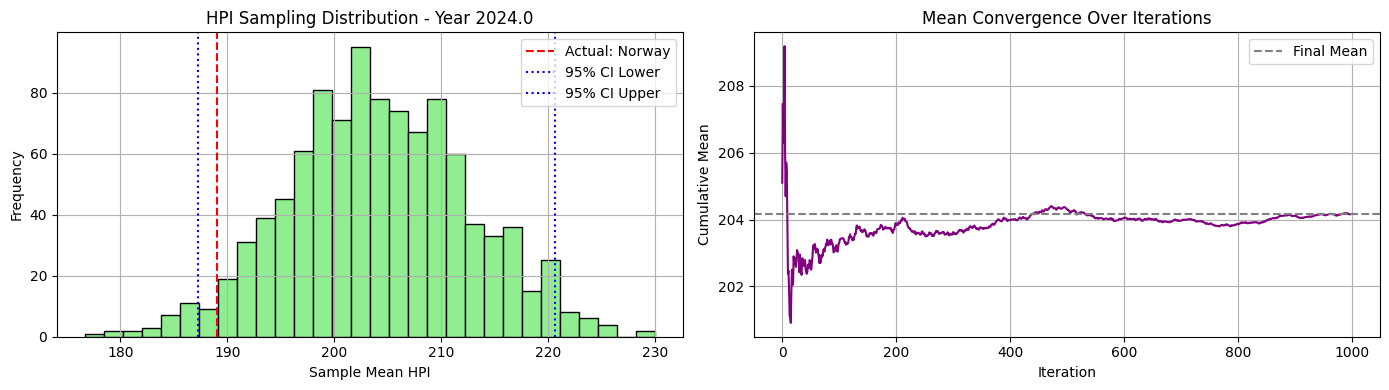

In [73]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(df_hpi_win2, clusters_c2_ni20_maxi500_h2, cluster_id=1)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [74]:
errors2 = {
    'cluster_0': [avg_mse_00, avg_mae_00],
    'cluster_1': [avg_mse_01, avg_mae_01]
}

In [75]:
# Convertir a DataFrame
df_errors2 = pd.DataFrame.from_dict(errors2, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors2 = df_errors2.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors2)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0    1028.7938      24.1077
cluster_1     693.1754      19.1414


In [76]:
variances2 = calculate_hpi_variance_by_cluster(df_hpi_win2, clusters_c2_ni20_maxi500_h2)
for cluster_id, var in variances2.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 988.5157
Cluster 1: Avg HPI Variance = 661.6471


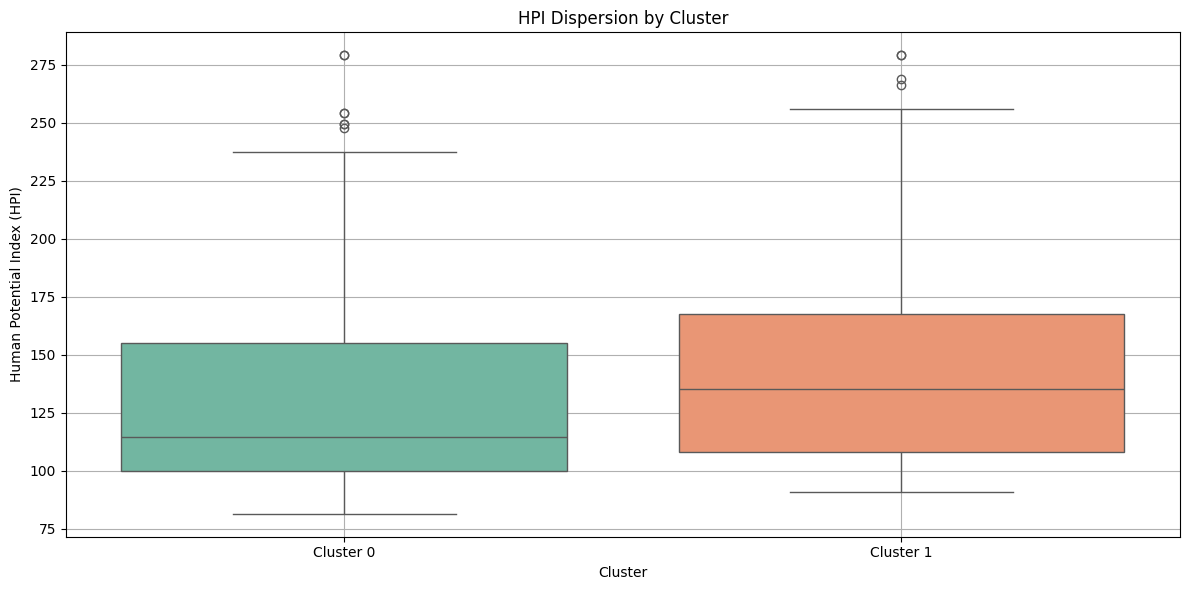

In [77]:
plot_hpi_dispersion_by_cluster(df_hpi_win2, clusters_c2_ni20_maxi500_h2)

In [78]:
iqr_percent2= percentage_points_within_iqr_by_cluster(df_hpi_win2, clusters_c2_ni20_maxi500_h2)
print(iqr_percent2)

{np.int32(0): np.float64(49.74), np.int32(1): np.float64(49.09)}


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [79]:
log_df = pd.read_parquet('../data/log_performance/new_log_performance.parquet')

In [80]:
pd.set_option('display.max_columns', None)

In [81]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,None,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,None,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN
2,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1090.584800,23.302850,hypothesis_test_015,None,None,956.43,1130.45,NaN,NaN,53.0,50.0,NaN,NaN
3,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1814.085733,29.407333,hypothesis_test_015,None,None,1228.13,1590.76,3058.83,871.95,46.0,76.0,37.0,48.0
4,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1118.876100,23.644450,hypothesis_test_013,None,None,1177.08,975.18,NaN,NaN,54.0,51.0,NaN,NaN
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,None,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,None,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN


In [82]:
new_entry3 = {
    'experiment_name': 'kmeans_++_2c_h2_4delete_countries_exclude',
    'experiment_date': '2025-09-17 15:31',
    'premacroecon_conversion_transform': None,
    'countries_used_for_clustering': 49,
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_c2_ni20_maxi500_h2,
    'transformations_clustering': 'StandardScaler, log transformation, Delete Countries x4',
    'outliers_handling_clustering': 'Winsorization x6',
    'used_all_variables_for_clustering': "['gdp', 'inflation', 'agr_land', 'livestock_prod']",
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 49,
    'mse_score': df_errors2['Average MSE'].mean(),
    'mae_score': df_errors2['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_024',
    'pca_ratio_sum': None,
    'pca_ratio_values': None,
    'Variance_Cluster_0': round(float(variances2[0]),2),
    'Variance_Cluster_1': round(float(variances2[1]),2),
    'Variance_Cluster_2': None,
    'Variance_Cluster_3': None,
    'IQR_Count_Cluster_0':int(iqr_percent2[0]),
    'IQR_Count_Cluster_1':int(iqr_percent2[1]),
    'IQR_Count_Cluster_2': None,
    'IQR_Count_Cluster_3': None   
}

In [83]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry3])], ignore_index=True)

C:\Users\lucas\AppData\Local\Temp\ipykernel_28052\1527126143.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log_df = pd.concat([log_df, pd.DataFrame([new_entry3])], ignore_index=True)


In [84]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
3,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1814.085733,29.407333,hypothesis_test_015,None,None,1228.13,1590.76,3058.83,871.95,46.0,76.0,37.0,48.0
4,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1118.876100,23.644450,hypothesis_test_013,None,None,1177.08,975.18,NaN,NaN,54.0,51.0,NaN,NaN
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,None,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,None,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN
7,kmeans_++_2c_h2_4delete_countries_exclude,2025-09-17 15:31,None,49,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420890,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,49.0,860.984600,21.624550,hypothesis_test_024,None,None,988.52,661.65,NaN,NaN,49.0,49.0,NaN,NaN


In [85]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [86]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,None,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,None,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN
2,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1090.584800,23.302850,hypothesis_test_015,None,None,956.43,1130.45,NaN,NaN,53.0,50.0,NaN,NaN
3,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1814.085733,29.407333,hypothesis_test_015,None,None,1228.13,1590.76,3058.83,871.95,46.0,76.0,37.0,48.0
4,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1118.876100,23.644450,hypothesis_test_013,None,None,1177.08,975.18,NaN,NaN,54.0,51.0,NaN,NaN
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,None,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,None,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN
7,kmeans_++_2c_h2_4delete_countries_exclude,2025-09-17 15:31,None,49,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420890,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,49.0,860.984600,21.624550,hypothesis_test_024,None,None,988.52,661.65,NaN,NaN,49.0,49.0,NaN,NaN


In [87]:
log_df.to_parquet('../data/log_performance/new_log_performance.parquet')